In [ ]:

import pandas as pd
import re
import string
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from collections import Counter

# Data Input
df = pd.read_csv("data/all_data.csv")
# Restrict analysis to the English language reviews
df = df[df["Review_Language"] == "English"].copy()
df["target"] = df["source"].map({0: "Human",1: "AI"})


df["Review"] = (df["Upside_Review"].fillna("") + " " +df["Downside_Review"].fillna(""))
df["Review"] = df["Review"].str.strip()

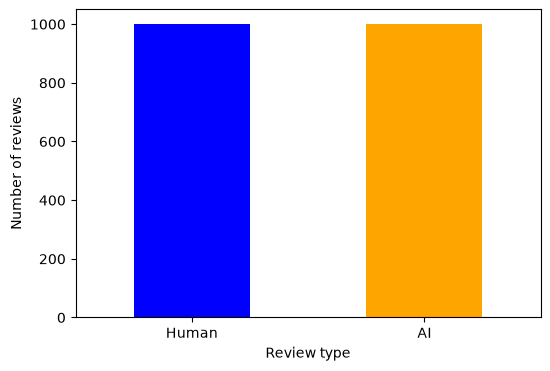

In [2]:
# Data distribution
source_counts = df["source"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
source_counts.plot(kind="bar",color=["blue", "orange"])
plt.xlabel("Review type")
plt.ylabel("Number of reviews")
plt.xticks([0, 1], ["Human", "AI"], rotation=0)
plt.show()

In [3]:
# Combine review columns
df["Review"] = (df["Upside_Review"].fillna("") + " " +df["Downside_Review"].fillna(""))
df["Review"] = df["Review"].str.strip()

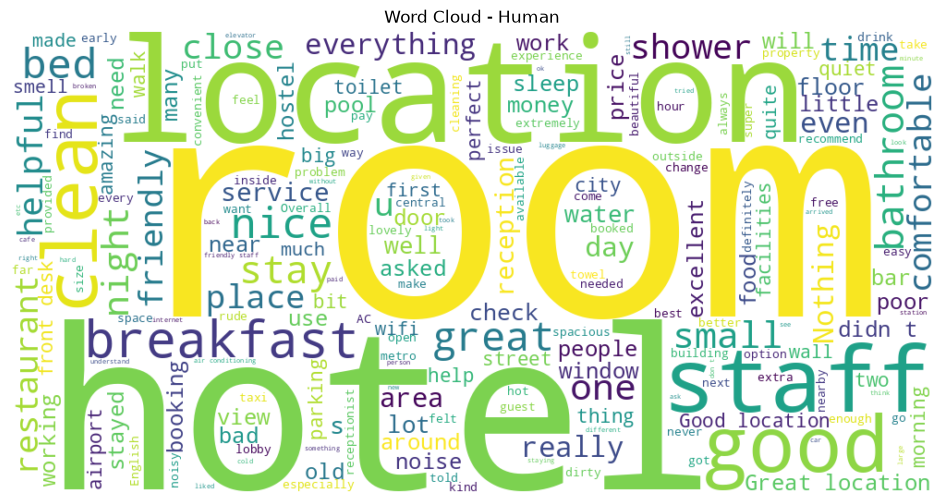

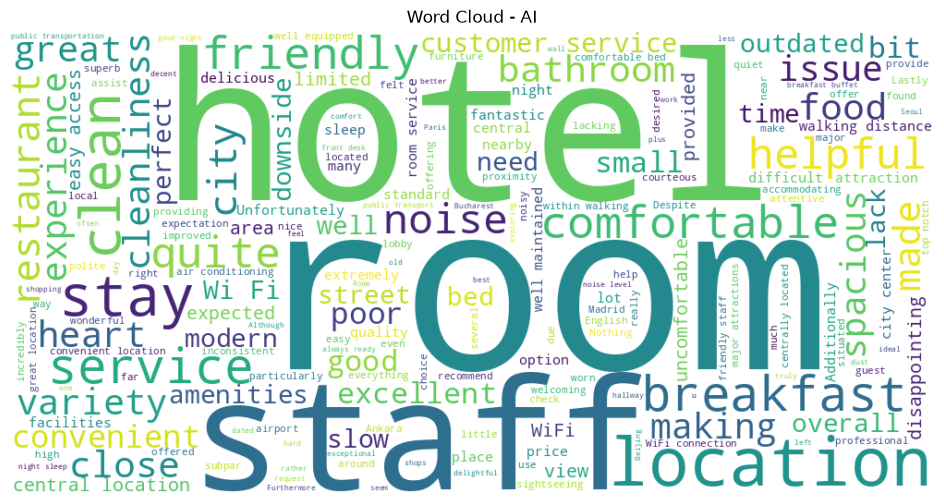

In [4]:
# Word Clouds: visualizing a review's most significant and frequently occurring words.
# Word Cloud Human
human_text = " ".join(df.loc[df["source"] == 0, "Review"].dropna())
wordcloud_human = WordCloud(width=1000, height=500,background_color="white").generate(human_text)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud_human, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud - Human")
plt.show()

# Word Cloud Fake
fake_text = " ".join(df.loc[df["source"] == 1, "Review"].dropna())
wordcloud_fake = WordCloud(width=1000, height=500, background_color="white").generate(fake_text)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud_fake, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud - AI")
plt.show()

In [5]:
# Evaluate differnces in vocabulary / word frequencies
def get_words(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    return text.split()

human_words = get_words(" ".join(df.loc[df["source"] == 0, "Review"].dropna()))
fake_words = get_words(" ".join(df.loc[df["source"] == 1, "Review"].dropna()))
human_common = Counter(human_words).most_common(20)
fake_common = Counter(fake_words).most_common(20)
print("Human:", human_common)
print("\nAI:", fake_common)

Human: [('the', 3210), ('and', 1662), ('was', 1344), ('to', 1231), ('a', 1083), ('in', 801), ('room', 743), ('i', 725), ('is', 672), ('of', 620), ('very', 572), ('it', 565), ('for', 541), ('not', 540), ('location', 525), ('hotel', 461), ('staff', 435), ('we', 432), ('good', 354), ('t', 352)]

AI: [('the', 5331), ('and', 2525), ('was', 2176), ('a', 1357), ('to', 1333), ('of', 1029), ('in', 885), ('hotel', 858), ('were', 765), ('location', 726), ('staff', 707), ('is', 656), ('not', 601), ('room', 597), ('rooms', 592), ('with', 589), ('it', 481), ('very', 397), ('for', 378), ('from', 375)]


In [6]:
# Evaluate differences in overall word count
df["word_count"] = df["Review"].fillna("").str.split().str.len()
print(df.groupby("source")["word_count"].agg(["count", "mean", "median", "std", "min", "max"]))

        count    mean  median        std  min  max
source                                            
0        1000  48.580    31.5  54.025608    2  548
1        1000  55.452    52.0  28.335677    5  172


In [7]:
pd.crosstab(df["Sentiment"],df["source"],normalize="columns")

source,0,1
Sentiment,,
NEG,0.5,0.5
POS,0.5,0.5


In [8]:
df_contr = df.copy()

# Normalize apostrophe types to ease detection 
df_contr["Review_analysis"] = (df_contr["Review"].fillna("").str.replace("’", "'", regex=False))

# Common English contractions
contraction_pattern = re.compile(
    r"\b(?:"
    r"[a-z]+n't|"                       # don't, didn't, isn't
    r"[a-z]+'(?:m|re|ve|ll|d)\b|"       # I'm, we're, they've, I'll
    r"it's|that's|there's|here's|"
    r"what's|who's|let's|"
    r"y'all|gonna|wanna|gotta"
    r")\b",
    flags=re.IGNORECASE
)

# Count contractions and words per review
df_contr["contraction_count"] = (df_contr["Review_analysis"].apply(lambda x: len(contraction_pattern.findall(x))))

df_contr["word_count"] = (df_contr["Review_analysis"].str.findall(r"\b[a-zA-Z]+\b").str.len())

df_contr["has_contraction"] = (df_contr["contraction_count"] > 0)

summary = df_contr.groupby("source").agg(
    reviews=("Review", "size"),
    reviews_with_contractions=("has_contraction", "sum"),
    total_contractions=("contraction_count", "sum"),
    total_words=("word_count", "sum")
)

summary["percentage_with_contractions"] = (
    summary["reviews_with_contractions"]
    / summary["reviews"] * 100
)

summary["contractions_per_1000_words"] = (
    summary["total_contractions"]
    / summary["total_words"] * 1000
)

print(summary.round(2))

        reviews  reviews_with_contractions  total_contractions  total_words  \
source                                                                        
0          1000                        282                 496        48530   
1          1000                        243                 313        56231   

        percentage_with_contractions  contractions_per_1000_words  
source                                                             
0                               28.2                        10.22  
1                               24.3                         5.57  


In [9]:

df_analysis = df.copy()
df_analysis["Review"] = df_analysis["Review"].fillna("")

# Word count
df_analysis["word_count"] = (df_analysis["Review"].str.findall(r"\b\w+\b").str.len())

# Count numeric sequences, e.g. 22, 2025, 4.5
df_analysis["number_count"] = (df_analysis["Review"].str.findall(r"\d+(?:[.,]\d+)?").str.len())

# Count selected punctuation marks
for char, name in [
    ("?", "question_marks"),
    ("!", "exclamation_marks"),
    (",", "commas"),
    (".", "periods"),
    (";", "semicolons"),
    (":", "colons"),
    ("'", "apostrophes"),
    ('"', "quotation_marks"),
]:
    df_analysis[name] = df_analysis["Review"].str.count(
        re.escape(char)
    )

# Summarize by source
count_columns = [
    "number_count",
    "question_marks",
    "exclamation_marks",
    "commas",
    "periods",
    "semicolons",
    "colons",
    "apostrophes",
    "quotation_marks",
]

summary = df_analysis.groupby("source").agg(
    reviews=("Review", "size"),
    total_words=("word_count", "sum"),
    **{
        col: (col, "sum")
        for col in count_columns
    }
)

# Normalize frequencies by text length
for col in count_columns:
    summary[f"{col}_per_1000_words"] = (
        summary[col] / summary["total_words"] * 1000
    )

print(summary.T)


source                                       0             1
reviews                            1000.000000   1000.000000
total_words                       49111.000000  56320.000000
number_count                        563.000000     47.000000
question_marks                       31.000000      1.000000
exclamation_marks                   278.000000     48.000000
commas                             1722.000000   2761.000000
periods                            3374.000000   4090.000000
semicolons                           32.000000     30.000000
colons                               66.000000      6.000000
apostrophes                         294.000000    518.000000
quotation_marks                      31.000000      0.000000
number_count_per_1000_words          11.463827      0.834517
question_marks_per_1000_words         0.631223      0.017756
exclamation_marks_per_1000_words      5.660646      0.852273
commas_per_1000_words                35.063428     49.023438
periods_per_1000_words  